
# MMA3001 — RetinaNet Four-Class Object Detection

## Aim
To train and evaluate a pretrained RetinaNet ResNet50-FPN V2 model
for detecting and localising pork rasher packaging defects.

## Defect Classes
1. loose-meat
2. packaging-error
3. twisted-meat
4. unsealed

The wrinkle class is excluded because the original dataset
contained only six independent source images for that class.

## Objectives
1. Adapt RetinaNet to the four-class dataset.
2. Train the model using pretrained COCO weights.
3. Select the best checkpoint using validation mAP@50:95.
4. Evaluate overall and per-class detection performance.
5. Compare confusion matrices at different confidence thresholds.
6. Analyse micro-F1, macro-F1 and computational efficiency.
7. Prepare results for comparison against YOLOv8n and Faster R-CNN.

## Evaluation Protocol
Training and validation data will be used for model development.
The test dataset will be reserved for final evaluation.



## 1. Environment Setup and Dataset Configuration

The required libraries are imported, and Google Drive is mounted to access the dataset and store experimental results. A fixed random seed is used to improve reproducibility.

The same four-class dataset used for YOLOv8n is selected to maintain consistent training, validation and testing splits across the models.


In [2]:

# Install evaluation libraries
%pip install -q torchmetrics pycocotools pandas matplotlib

# Mount Google Drive for dataset and checkpoint storage
from google.colab import drive
drive.mount("/content/drive")

# General libraries
from pathlib import Path
from PIL import Image
from functools import partial
import random
import time
import shutil

# Numerical and plotting libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.ops import box_iou

# RetinaNet
from torchvision.models.detection import (
    retinanet_resnet50_fpn_v2,
    RetinaNet_ResNet50_FPN_V2_Weights
)
from torchvision.models.detection.retinanet import (
    RetinaNetClassificationHead
)

# Detection evaluation
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# GPU configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Training on CPU will be slow.")


Mounted at /content/drive
Device: cuda
GPU: Tesla T4


In [3]:

# Original four-class dataset
dataset_root = Path(
    "/content/drive/MyDrive/MMA3001_Project/"
    "dataset/pork_rasher_v4_4class"
)

# Directory for RetinaNet outputs
run_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/"
    "model_runs/retinanet_resnet50_4class"
)

run_dir.mkdir(parents=True, exist_ok=True)

# Checkpoint path
best_model_path = run_dir / "best.pt"

# Four defect classes
CLASS_NAMES = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed"
]

NUM_CLASSES = len(CLASS_NAMES)

# RetinaNet uses shifted labels:
# 0 = reserved/background
# 1 = loose-meat
# 2 = packaging-error
# 3 = twisted-meat
# 4 = unsealed

print("Dataset exists:", dataset_root.exists())
print("Dataset:", dataset_root)
print("Output directory:", run_dir)

assert dataset_root.exists(), "Dataset directory not found!"

for split in ["train", "valid", "test"]:
    images_dir = dataset_root / split / "images"
    labels_dir = dataset_root / split / "labels"

    assert images_dir.exists(), f"Missing: {images_dir}"
    assert labels_dir.exists(), f"Missing: {labels_dir}"

    print(f"{split}: directories verified")


Dataset exists: True
Dataset: /content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class
Output directory: /content/drive/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_4class
train: directories verified
valid: directories verified
test: directories verified



## 2. Dataset Preparation for RetinaNet

The original dataset uses YOLO annotations with normalised centre coordinates, width and height. These annotations are converted into absolute bounding-box coordinates (x_min, y_min, x_max, y_max), as required by Torchvision RetinaNet.

Class labels are also shifted from 0–3 to 1–4, with index 0 reserved for background. Images without annotated defects are retained as background examples.


In [4]:

class PorkRasherDataset(Dataset):
    """
    PyTorch dataset for four-class pork rasher detection.

    Converts:
        YOLO normalised xywh annotations
    Into:
        Absolute xyxy bounding boxes

    Also shifts labels by +1 for the RetinaNet
    class-index convention used in this project.
    """

    def __init__(self, root, split):

        self.root = Path(root)
        self.split = split

        self.images_dir = (
            self.root / split / "images"
        )

        self.labels_dir = (
            self.root / split / "labels"
        )

        self.image_paths = sorted([
            p for p in self.images_dir.iterdir()
            if p.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".webp"
            }
        ])

        assert len(self.image_paths) > 0, (
            f"No images in {self.images_dir}"
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image_path = self.image_paths[idx]

        image = Image.open(
            image_path
        ).convert("RGB")

        width, height = image.size

        label_path = (
            self.labels_dir /
            f"{image_path.stem}.txt"
        )

        boxes = []
        labels = []

        if label_path.exists():

            lines = label_path.read_text().splitlines()

            for line in lines:

                if not line.strip():
                    continue

                values = list(map(float, line.split()))

                assert len(values) == 5, (
                    f"Invalid annotation: {label_path}"
                )

                class_id = int(values[0])

                assert 0 <= class_id < NUM_CLASSES

                xc, yc, bw, bh = values[1:]

                # Convert normalised xywh to xyxy
                x1 = (xc - bw / 2) * width
                y1 = (yc - bh / 2) * height

                x2 = (xc + bw / 2) * width
                y2 = (yc + bh / 2) * height

                # Clamp coordinates within image
                x1 = max(0, min(x1, width))
                y1 = max(0, min(y1, height))

                x2 = max(0, min(x2, width))
                y2 = max(0, min(y2, height))

                if x2 <= x1 or y2 <= y1:
                    raise ValueError(
                        f"Invalid box in {label_path}"
                    )

                boxes.append([x1, y1, x2, y2])

                # Shift 0-3 into 1-4
                labels.append(class_id + 1)

        boxes = torch.tensor(
            boxes, dtype=torch.float32
        ).reshape(-1, 4)

        labels = torch.tensor(
            labels, dtype=torch.int64
        )

        # Additional target fields
        area = (
            (boxes[:, 2] - boxes[:, 0]) *
            (boxes[:, 3] - boxes[:, 1])
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(idx),
            "area": area,
            "iscrowd": torch.zeros(
                len(labels), dtype=torch.int64
            )
        }

        # Convert RGB image to float tensor [0, 1]
        image = TF.to_tensor(image)

        return image, target



## 3. Data Loading and Annotation Verification

The dataset is copied from Google Drive to local Colab storage to reduce data-loading overhead during training. Separate DataLoaders are created for the training and validation sets.

Class distributions are checked, and sample annotations are visualised to verify that bounding boxes and class labels were converted correctly before model training.


In [5]:

# Copy dataset to faster local Colab storage
USE_LOCAL_COPY = True

if USE_LOCAL_COPY:

    local_dataset_root = Path(
        "/content/pork_rasher_v4_4class"
    )

    if not local_dataset_root.exists():

        print("Copying dataset to local Colab storage...")

        shutil.copytree(
            dataset_root,
            local_dataset_root
        )

    active_root = local_dataset_root

else:
    active_root = dataset_root


# Create datasets
train_dataset = PorkRasherDataset(
    active_root, "train"
)

valid_dataset = PorkRasherDataset(
    active_root, "valid"
)

test_dataset = PorkRasherDataset(
    active_root, "test"
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))


# Count class annotations
for split_name, dataset in [
    ("Train", train_dataset),
    ("Valid", valid_dataset),
    ("Test", test_dataset)
]:

    counts = np.zeros(NUM_CLASSES, dtype=int)

    for _, target in dataset:

        for label in target["labels"]:
            counts[int(label) - 1] += 1

    print(f"\n{split_name} class distribution:")

    for name, count in zip(CLASS_NAMES, counts):
        print(f"{name}: {count}")


# Detection images contain different numbers of boxes,
# so use a custom collation function.
def collate_fn(batch):
    return tuple(zip(*batch))


BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn,
    pin_memory=(device.type == "cuda")
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn,
    pin_memory=(device.type == "cuda")
)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(valid_loader))


Copying dataset to local Colab storage...
Training images: 3138
Validation images: 120
Test images: 80

Train class distribution:
loose-meat: 60
packaging-error: 1616
twisted-meat: 70
unsealed: 994

Valid class distribution:
loose-meat: 3
packaging-error: 34
twisted-meat: 3
unsealed: 81

Test class distribution:
loose-meat: 3
packaging-error: 23
twisted-meat: 4
unsealed: 49

Training batches: 785
Validation batches: 30


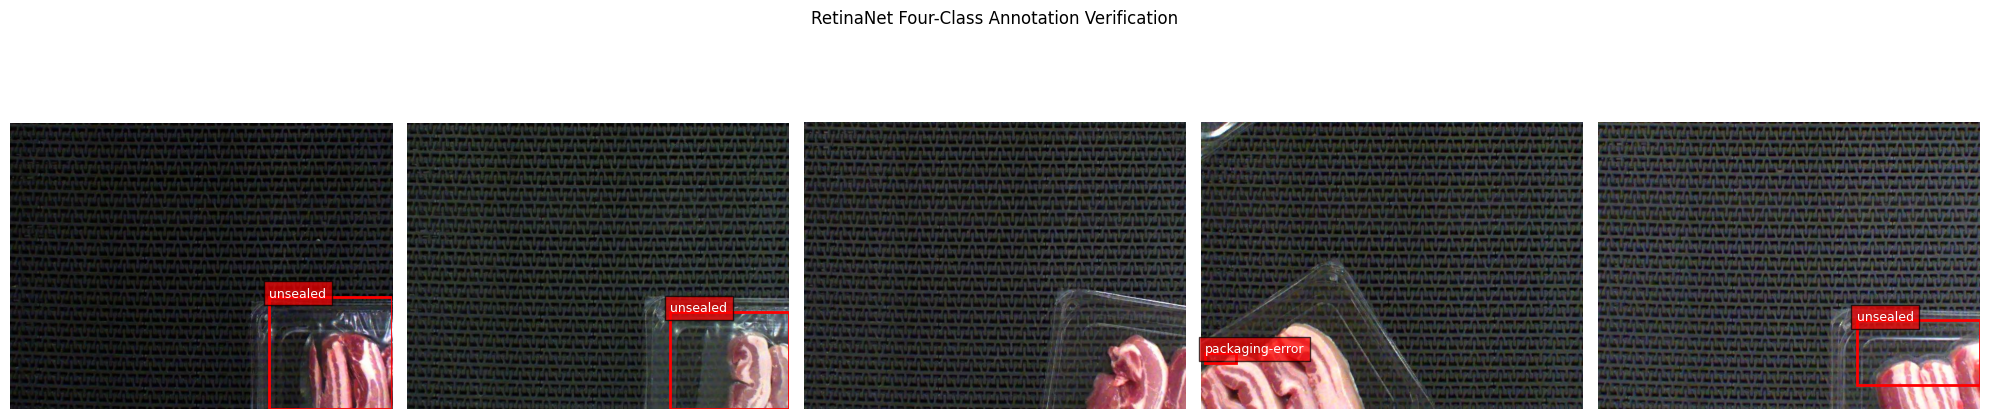

In [6]:

# Randomly select five training samples
random.seed(SEED)

sample_indices = random.sample(
    range(len(train_dataset)),
    min(5, len(train_dataset))
)

fig, axes = plt.subplots(
    1,
    len(sample_indices),
    figsize=(20, 5)
)

axes = np.atleast_1d(axes)

for ax, idx in zip(axes, sample_indices):

    image, target = train_dataset[idx]

    # Convert tensor to displayable RGB image
    image_np = image.permute(1, 2, 0).numpy()

    ax.imshow(image_np)

    for box, label in zip(
        target["boxes"],
        target["labels"]
    ):

        x1, y1, x2, y2 = box.tolist()

        class_name = CLASS_NAMES[
            int(label) - 1
        ]

        rectangle = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            x1, y1,
            class_name,
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.7}
        )

    ax.axis("off")

plt.suptitle(
    "RetinaNet Four-Class Annotation Verification"
)

plt.tight_layout()
plt.show()



## 4. RetinaNet Model Initialisation

RetinaNet with a ResNet50-FPN V2 backbone is initialised using pretrained COCO weights. Its classification head is replaced to support the four packaging-defect classes.

The model uses a feature pyramid network for multi-scale feature extraction and focal loss to reduce the influence of easily classified examples during training.

A forward-pass test is performed to verify that the model accepts the converted annotations and produces valid training losses.


In [7]:

# Load pretrained COCO RetinaNet model
weights = RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT

retinanet = retinanet_resnet50_fpn_v2(
    weights=weights,
    min_size=640,
    max_size=640
)

# Number of features from FPN backbone
in_channels = retinanet.backbone.out_channels

# Number of anchor boxes per spatial position
num_anchors = (
    retinanet.anchor_generator
    .num_anchors_per_location()[0]
)

# Four defects plus reserved background class
num_model_classes = NUM_CLASSES + 1

# Replace pretrained classification head
retinanet.head.classification_head = (
    RetinaNetClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=num_model_classes,
        norm_layer=partial(nn.GroupNorm, 32)
    )
)

# Maximum predictions retained per image
retinanet.detections_per_img = 100

# Transfer model to GPU
retinanet = retinanet.to(device)

# Calculate model complexity
total_params = sum(
    p.numel() for p in retinanet.parameters()
)

trainable_params = sum(
    p.numel()
    for p in retinanet.parameters()
    if p.requires_grad
)

print("Architecture: RetinaNet ResNet50-FPN V2")
print("Pretrained weights: COCO")
print("Number of model classes:", num_model_classes)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 165MB/s]


Architecture: RetinaNet ResNet50-FPN V2
Pretrained weights: COCO
Number of model classes: 5
Total parameters: 36414865
Trainable parameters: 36189521


In [8]:

# Obtain a single training batch
images, targets = next(iter(train_loader))

images = [
    image.to(device)
    for image in images
]

targets = [
    {
        key: value.to(device)
        for key, value in target.items()
    }
    for target in targets
]

# Training mode produces loss dictionary
retinanet.train()

with torch.no_grad():

    loss_dict = retinanet(
        images,
        targets
    )

print("RetinaNet training losses:")

for name, value in loss_dict.items():
    print(f"{name}: {value.item():.4f}")

print(
    "Total loss:",
    sum(loss_dict.values()).item()
)

# Return to evaluation mode
retinanet.eval()


RetinaNet training losses:
classification: 1.1137
bbox_regression: 0.3790
Total loss: 1.4926362037658691


RetinaNet(
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      


## 5. Model Training and Validation

The model is fine-tuned for 15 epochs using stochastic gradient descent (SGD) and mixed-precision training to reduce computational requirements.

Validation is performed after each epoch using mAP@50 and mAP@50:95. The checkpoint with the highest validation mAP@50:95 is saved rather than automatically selecting the final epoch.

This allows training convergence and potential overfitting to be examined.


In [9]:

@torch.no_grad()
def evaluate_model(model, data_loader):
    """
    Evaluate a Torchvision object detector.

    Returns:
        mAP@50
        mAP@50:95
        Per-class AP

    Uses COCO-style object detection evaluation.
    """

    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=True
    )

    for images, targets in data_loader:

        images = [
            image.to(device)
            for image in images
        ]

        predictions = model(images)

        # Move predictions to CPU for metric computation
        predictions_cpu = [
            {
                "boxes": p["boxes"].detach().cpu(),
                "scores": p["scores"].detach().cpu(),
                "labels": p["labels"].detach().cpu()
            }
            for p in predictions
        ]

        targets_cpu = [
            {
                "boxes": t["boxes"].cpu(),
                "labels": t["labels"].cpu()
            }
            for t in targets
        ]

        metric.update(
            predictions_cpu,
            targets_cpu
        )

    return metric.compute()


In [10]:

# ---------------------------------------
# Training configuration
# ---------------------------------------
NUM_EPOCHS = 15
LEARNING_RATE = 0.005

optimizer = torch.optim.SGD(
    retinanet.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=0.0005
)

# Reduce learning rate every 5 epochs
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

# Mixed precision for CUDA acceleration
amp_enabled = (device.type == "cuda")

# Create scaler once, outside the training loop
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

history = []
best_map = -1.0

training_start = time.perf_counter()

# ---------------------------------------
# Main training loop
# ---------------------------------------
for epoch in range(1, NUM_EPOCHS + 1):

    retinanet.train()

    epoch_loss = 0.0
    epoch_start = time.perf_counter()

    for batch_idx, (images, targets) in enumerate(
        train_loader, start=1
    ):

        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        targets = [
            {
                key: value.to(device, non_blocking=True)
                for key, value in target.items()
            }
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision
        with torch.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):

            loss_dict = retinanet(
                images,
                targets
            )

            total_loss = sum(loss_dict.values())

        # Backpropagation
        scaler.scale(total_loss).backward()

        # Update model weights
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += total_loss.item()

        if batch_idx % 50 == 0:

            print(
                f"Epoch {epoch}/{NUM_EPOCHS} | "
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss {total_loss.item():.4f}"
            )

    # ---------------------------------------
    # End-of-epoch validation
    # ---------------------------------------
    avg_train_loss = epoch_loss / len(train_loader)

    val_results = evaluate_model(
        retinanet,
        valid_loader
    )

    val_map = float(val_results["map"])
    val_map50 = float(val_results["map_50"])

    epoch_seconds = (
        time.perf_counter() - epoch_start
    )

    # Record training results
    history.append({
        "Epoch": epoch,
        "Train_Loss": avg_train_loss,
        "Val_mAP50": val_map50,
        "Val_mAP50_95": val_map,
        "Epoch_Seconds": epoch_seconds
    })

    # Save training history after every epoch
    pd.DataFrame(history).to_csv(
        run_dir / "training_history.csv",
        index=False
    )

    # ---------------------------------------
    # Select best validation checkpoint
    # ---------------------------------------
    if val_map > best_map:

        best_map = val_map

        checkpoint = {
            "model_state": retinanet.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "epoch": epoch,
            "val_map": val_map
        }

        torch.save(
            checkpoint,
            best_model_path
        )

        print("New best checkpoint saved!")

    scheduler.step()

    print(
        f"\nEpoch {epoch}/{NUM_EPOCHS}"
        f"\nTraining Loss: {avg_train_loss:.4f}"
        f"\nValidation mAP@50: {val_map50:.4f}"
        f"\nValidation mAP@50:95: {val_map:.4f}"
        f"\nEpoch Time: {epoch_seconds:.1f} s"
        f"\nBest mAP@50:95: {best_map:.4f}\n"
    )


# ---------------------------------------
# Training completion
# ---------------------------------------
training_seconds = (
    time.perf_counter() - training_start
)

print("TRAINING COMPLETED")
print("Training time (s):", round(training_seconds, 2))
print("Best validation mAP@50:95:", round(best_map, 4))
print("Best checkpoint:", best_model_path)

assert best_model_path.exists()


Epoch 1/15 | Batch 50/785 | Loss 0.7578
Epoch 1/15 | Batch 100/785 | Loss 1.0689
Epoch 1/15 | Batch 150/785 | Loss 0.9258
Epoch 1/15 | Batch 200/785 | Loss 1.0669
Epoch 1/15 | Batch 250/785 | Loss 0.8672
Epoch 1/15 | Batch 300/785 | Loss 0.8294
Epoch 1/15 | Batch 350/785 | Loss 0.9239
Epoch 1/15 | Batch 400/785 | Loss 0.6551
Epoch 1/15 | Batch 450/785 | Loss 0.8890
Epoch 1/15 | Batch 500/785 | Loss 0.8494
Epoch 1/15 | Batch 550/785 | Loss 0.7162
Epoch 1/15 | Batch 600/785 | Loss 0.8491
Epoch 1/15 | Batch 650/785 | Loss 0.9495
Epoch 1/15 | Batch 700/785 | Loss 0.4468
Epoch 1/15 | Batch 750/785 | Loss 0.3345
New best checkpoint saved!

Epoch 1/15
Training Loss: 0.8028
Validation mAP@50: 0.2016
Validation mAP@50:95: 0.1283
Epoch Time: 160.0 s
Best mAP@50:95: 0.1283

Epoch 2/15 | Batch 50/785 | Loss 0.2574
Epoch 2/15 | Batch 100/785 | Loss 0.4474
Epoch 2/15 | Batch 150/785 | Loss 0.7296
Epoch 2/15 | Batch 200/785 | Loss 0.6795
Epoch 2/15 | Batch 250/785 | Loss 0.6368
Epoch 2/15 | Batch 300

,Epoch,Train_Loss,Val_mAP50,Val_mAP50_95,Epoch_Seconds
0,1,0.8028,0.2016,0.1283,159.9506
1,2,0.5396,0.2425,0.1498,154.7055
2,3,0.4764,0.2534,0.1366,154.9889
3,4,0.3652,0.2575,0.1556,152.3259
4,5,0.2960,0.3173,0.1838,154.7817
5,6,0.2168,0.2651,0.1537,155.3439
6,7,0.1734,0.2692,0.1583,153.7219
7,8,0.1501,0.3088,0.1737,152.9863
8,9,0.1339,0.2809,0.1618,152.1868
9,10,0.1193,0.3622,0.2168,152.2310


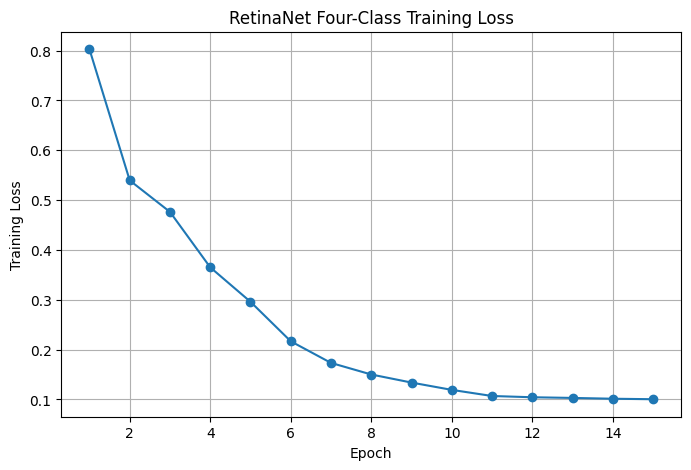

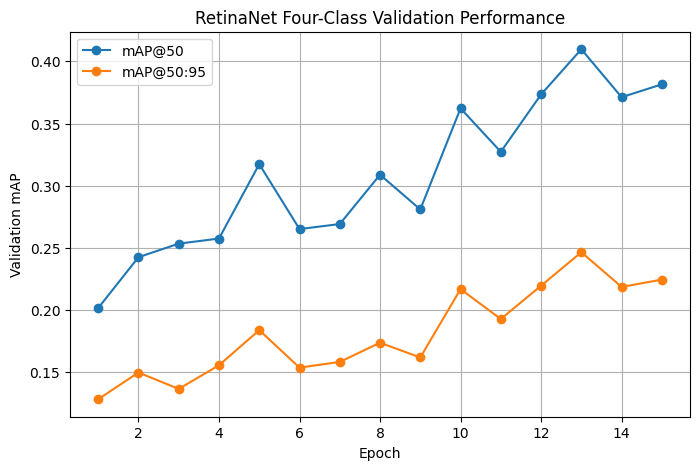

Best epoch: 13
Best validation mAP@50:95: 0.2465


In [11]:

# Load training history
history_df = pd.read_csv(
    run_dir / "training_history.csv"
)

display(history_df.round(4))

# Training loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train_Loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("RetinaNet Four-Class Training Loss")
plt.grid(True)

plt.savefig(
    run_dir / "training_loss.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# Validation mAP
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Val_mAP50"],
    marker="o",
    label="mAP@50"
)

plt.plot(
    history_df["Epoch"],
    history_df["Val_mAP50_95"],
    marker="o",
    label="mAP@50:95"
)

plt.xlabel("Epoch")
plt.ylabel("Validation mAP")
plt.title("RetinaNet Four-Class Validation Performance")
plt.legend()
plt.grid(True)

plt.savefig(
    run_dir / "validation_map.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# Identify best epoch
best_epoch = history_df.loc[
    history_df["Val_mAP50_95"].idxmax()
]

print("Best epoch:", int(best_epoch["Epoch"]))
print(
    "Best validation mAP@50:95:",
    round(best_epoch["Val_mAP50_95"], 4)
)



## 6. Training Performance Analysis

Training loss and validation mAP are plotted against the number of epochs to examine model convergence and generalisation.

A decreasing training loss without corresponding validation improvement may indicate overfitting. The best-performing checkpoint is reloaded for subsequent evaluation.


In [12]:

# Load saved best model
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

retinanet.load_state_dict(
    checkpoint["model_state"]
)

retinanet = retinanet.to(device)
retinanet.eval()

print("Best checkpoint loaded")
print("Selected epoch:", checkpoint["epoch"])
print(
    "Saved validation mAP@50:95:",
    checkpoint["val_map"]
)


Best checkpoint loaded
Selected epoch: 13
Saved validation mAP@50:95: 0.24650931358337402


In [13]:

# Evaluate best checkpoint
validation_results = evaluate_model(
    retinanet,
    valid_loader
)

print("4-CLASS RETINANET VALIDATION RESULTS")
print("-----------------------------------")

print(
    "mAP@50:",
    round(float(validation_results["map_50"]), 4)
)

print(
    "mAP@50:95:",
    round(float(validation_results["map"]), 4)
)

# Per-class AP
per_class_rows = []

for class_id, ap in zip(
    validation_results["classes"],
    validation_results["map_per_class"]
):

    index = int(class_id) - 1

    per_class_rows.append({
        "Class": CLASS_NAMES[index],
        "mAP@50:95": float(ap)
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\nPER-CLASS mAP@50:95")
display(per_class_df.round(4))

# Save results
per_class_df.to_csv(
    run_dir / "per_class_ap.csv",
    index=False
)


4-CLASS RETINANET VALIDATION RESULTS
-----------------------------------
mAP@50: 0.4098
mAP@50:95: 0.2465

PER-CLASS mAP@50:95


,Class,mAP@50:95
0,loose-meat,0.1727
1,packaging-error,0.0545
2,twisted-meat,0.2020
3,unsealed,0.5569



## 7. Overall and Per-Class Detection Performance

The selected checkpoint is evaluated on the validation dataset using mAP@50 and mAP@50:95.

Per-class average precision is also calculated to identify differences in detection performance between defect categories. This is particularly important because the dataset contains substantial class imbalance.


In [14]:

@torch.no_grad()
def collect_predictions(model, data_loader):
    """
    Collect predictions and ground-truth annotations.

    Predictions are stored on CPU to avoid
    repeated GPU inference during threshold sweeps.
    """

    model.eval()

    predictions_all = []
    targets_all = []

    for images, targets in data_loader:

        images_gpu = [
            image.to(device)
            for image in images
        ]

        predictions = model(images_gpu)

        for prediction, target in zip(
            predictions,
            targets
        ):

            predictions_all.append({
                "boxes": prediction["boxes"].cpu(),
                "scores": prediction["scores"].cpu(),
                "labels": prediction["labels"].cpu()
            })

            targets_all.append({
                "boxes": target["boxes"].cpu(),
                "labels": target["labels"].cpu()
            })

    return predictions_all, targets_all


predictions_all, targets_all = collect_predictions(
    retinanet,
    valid_loader
)

print("Prediction images:", len(predictions_all))
print("Ground-truth images:", len(targets_all))

print("Internal score threshold:", retinanet.score_thresh)
print("NMS threshold:", retinanet.nms_thresh)
print("Maximum detections:", retinanet.detections_per_img)

assert len(predictions_all) == len(targets_all)


Prediction images: 120
Ground-truth images: 120
Internal score threshold: 0.05
NMS threshold: 0.5
Maximum detections: 100



## 8. Confidence Threshold Evaluation

Predictions are collected from the validation dataset and evaluated at confidence thresholds of 0.10, 0.25, 0.50, 0.70 and 0.849.

Bounding boxes are matched to ground-truth annotations using an IoU threshold of 0.50. Confusion matrices and overall performance metrics are calculated to examine the relationship between false positives, missed detections and confidence thresholds.

Micro-F1 measures overall detection performance, while macro-F1 gives equal importance to each defect class.


In [22]:

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

N = NUM_CLASSES
BACKGROUND = N

MATRIX_LABELS = CLASS_NAMES + ["background"]


def make_confusion_matrix(threshold):
    """
    Create a class-aware detection confusion matrix.

    Matching:
      - Sort predictions by confidence
      - Match each prediction to one unused ground truth
      - Require IoU >= 0.50
      - Unmatched predictions count as background FP
      - Unmatched ground truths count as background FN

    Returns a (5 x 5) matrix.
    """

    cm = np.zeros(
        (N + 1, N + 1),
        dtype=int
    )

    for prediction, target in zip(
        predictions_all,
        targets_all
    ):

        # Apply confidence threshold
        keep = (
            prediction["scores"] >= threshold
        )

        pred_boxes = prediction["boxes"][keep]
        pred_scores = prediction["scores"][keep]
        pred_labels = prediction["labels"][keep]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        # Sort by descending confidence
        order = torch.argsort(
            pred_scores,
            descending=True
        )

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        # Match predictions to actual objects
        for pred_box, pred_label in zip(
            pred_boxes,
            pred_labels
        ):

            # Convert labels 1-4 back to 0-3
            pred_index = int(pred_label) - 1

            if not (0 <= pred_index < N):
                continue

            if len(gt_boxes) == 0:

                cm[pred_index, BACKGROUND] += 1
                continue

            ious = box_iou(
                pred_box.unsqueeze(0),
                gt_boxes
            )[0]

            # Prevent duplicate GT matching
            for index in matched_gt:
                ious[index] = -1

            best_iou, best_index = ious.max(0)
            best_index = int(best_index)

            if best_iou >= IOU_THRESHOLD:

                true_index = (
                    int(gt_labels[best_index]) - 1
                )

                cm[pred_index, true_index] += 1
                matched_gt.add(best_index)

            else:

                cm[pred_index, BACKGROUND] += 1

        # Count undetected ground truths
        for gt_index, gt_label in enumerate(gt_labels):

            if gt_index not in matched_gt:

                true_index = int(gt_label) - 1

                cm[BACKGROUND, true_index] += 1

    return cm


In [16]:

def calculate_metrics(cm, threshold):
    """
    Calculate overall and per-class performance
    from a detection confusion matrix.
    """

    # Correct classification and localisation
    tp = int(np.trace(cm[:N, :N]))

    # Includes wrong-class predictions
    fp = int(cm[:N, :].sum() - tp)

    # Includes missed and misclassified ground truths
    fn = int(cm[:, :N].sum() - tp)

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else 0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0 else 0
    )

    micro_f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    class_f1_values = []

    result = {
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "Micro-F1": micro_f1
    }

    for i, class_name in enumerate(CLASS_NAMES):

        class_tp = cm[i, i]

        class_fp = (
            cm[i, :].sum() - class_tp
        )

        class_fn = (
            cm[:, i].sum() - class_tp
        )

        class_precision = (
            class_tp / (class_tp + class_fp)
            if class_tp + class_fp > 0 else 0
        )

        class_recall = (
            class_tp / (class_tp + class_fn)
            if class_tp + class_fn > 0 else 0
        )

        class_f1 = (
            2 * class_precision * class_recall
            / (class_precision + class_recall)
            if class_precision + class_recall > 0 else 0
        )

        class_f1_values.append(class_f1)

        result[class_name + "_TP"] = int(class_tp)
        result[class_name + "_Recall"] = class_recall

    result["Macro-F1"] = np.mean(
        class_f1_values
    )

    return result


# Evaluate five thresholds
matrices = [
    make_confusion_matrix(t)
    for t in THRESHOLDS
]

summary_df = pd.DataFrame([
    calculate_metrics(cm, threshold)
    for cm, threshold in zip(matrices, THRESHOLDS)
])

print("OVERALL THRESHOLD COMPARISON")

display(
    summary_df[
        [
            "Threshold", "TP", "FP", "FN",
            "Precision", "Recall",
            "Micro-F1", "Macro-F1"
        ]
    ].round(4)
)

summary_df.to_csv(
    run_dir / "threshold_comparison.csv",
    index=False
)


OVERALL THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,Micro-F1,Macro-F1
0,0.100,91,498,30,0.1545,0.7521,0.2563,0.2123
1,0.250,87,73,34,0.5438,0.7190,0.6192,0.2873
2,0.500,82,32,39,0.7193,0.6777,0.6979,0.3016
3,0.700,77,21,44,0.7857,0.6364,0.7032,0.2854
4,0.849,72,12,49,0.8571,0.5950,0.7024,0.2736


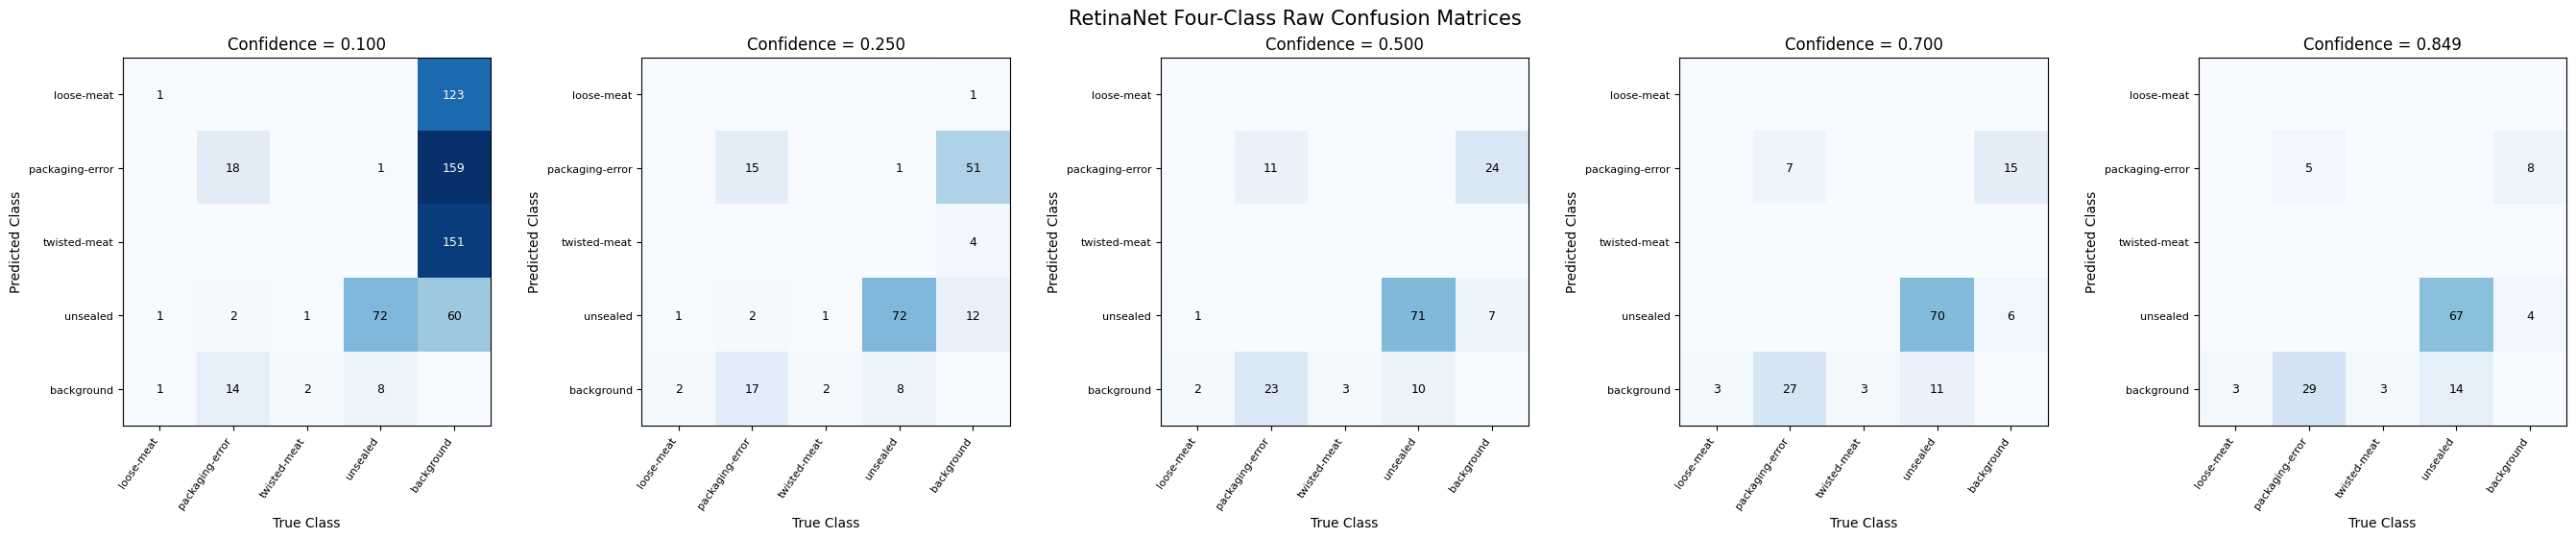

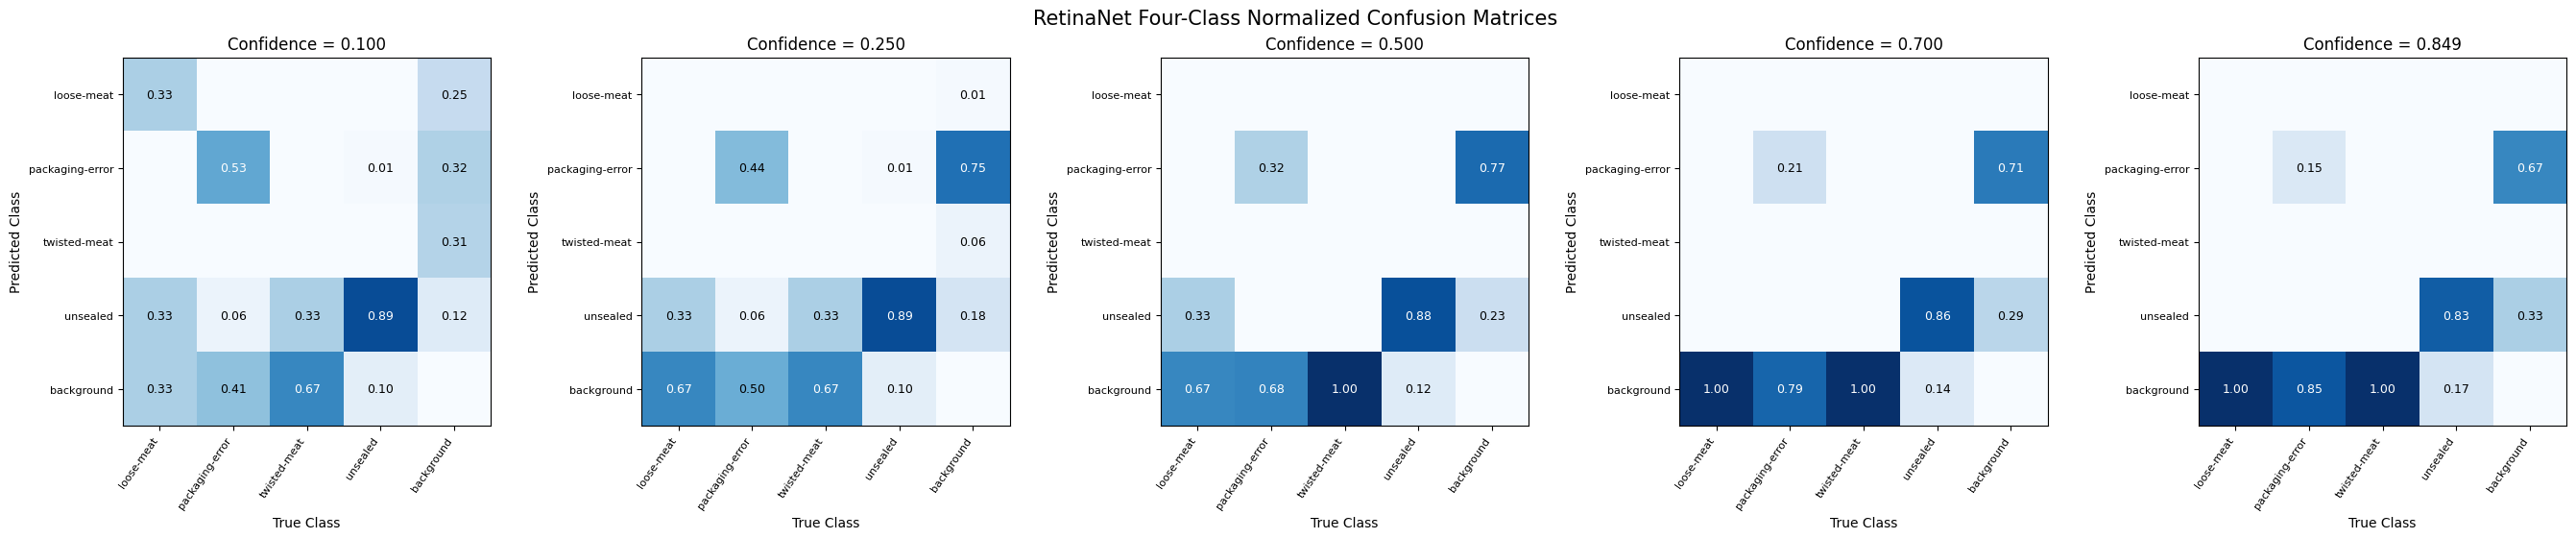

In [17]:

def plot_confusion_matrices(
    matrices,
    thresholds,
    normalized=False
):

    fig, axes = plt.subplots(
        1,
        len(thresholds),
        figsize=(27, 5.5),
        constrained_layout=True
    )

    max_value = (
        1.0 if normalized
        else max(cm.max() for cm in matrices)
    )

    for ax, threshold, cm in zip(
        axes, thresholds, matrices
    ):

        if normalized:

            column_sums = cm.sum(
                axis=0, keepdims=True
            )

            data = np.divide(
                cm.astype(float),
                column_sums,
                out=np.zeros_like(cm, dtype=float),
                where=column_sums != 0
            )

        else:
            data = cm

        ax.imshow(
            data,
            cmap="Blues",
            vmin=0,
            vmax=max_value
        )

        ax.set_title(
            f"Confidence = {threshold:.3f}"
        )

        ax.set_xticks(range(N + 1))
        ax.set_yticks(range(N + 1))

        ax.set_xticklabels(
            MATRIX_LABELS,
            rotation=55,
            ha="right",
            fontsize=8
        )

        ax.set_yticklabels(
            MATRIX_LABELS,
            fontsize=8
        )

        ax.set_xlabel("True Class")
        ax.set_ylabel("Predicted Class")

        for row in range(N + 1):
            for col in range(N + 1):

                value = data[row, col]

                if value > 0:

                    text_value = (
                        f"{value:.2f}"
                        if normalized
                        else str(value)
                    )

                    ax.text(
                        col, row,
                        text_value,
                        ha="center",
                        va="center",
                        fontsize=9,
                        color=(
                            "white"
                            if value > max_value / 2
                            else "black"
                        )
                    )

    matrix_type = (
        "Normalized"
        if normalized
        else "Raw"
    )

    fig.suptitle(
        f"RetinaNet Four-Class {matrix_type} "
        "Confusion Matrices",
        fontsize=15
    )

    filename = (
        "confusion_matrices_normalized.png"
        if normalized
        else "confusion_matrices_raw.png"
    )

    fig.savefig(
        run_dir / filename,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()


# Raw confusion matrices
plot_confusion_matrices(
    matrices,
    THRESHOLDS,
    normalized=False
)

# Normalised confusion matrices
plot_confusion_matrices(
    matrices,
    THRESHOLDS,
    normalized=True
)



## 9. Confusion Matrix Analysis

Raw and normalised confusion matrices are generated for each confidence threshold.

The raw matrices show the number of correct detections, misclassifications, false positives and false negatives. The normalised matrices show the distribution of predictions for each actual class, allowing class-specific detection behaviour to be compared more easily.


FINE CONFIDENCE THRESHOLD SWEEP


,Threshold,Precision,Recall,Micro-F1,Macro-F1
0,0.100,0.1545,0.7521,0.2563,0.2123
1,0.125,0.2055,0.7438,0.3220,0.2429
2,0.150,0.2744,0.7438,0.4009,0.2605
3,0.175,0.3574,0.7355,0.4811,0.2810
4,0.200,0.4314,0.7273,0.5415,0.3142
5,0.225,0.5029,0.7190,0.5918,0.2806
6,0.250,0.5438,0.7190,0.6192,0.2873
7,0.275,0.5733,0.7107,0.6347,0.2867
8,0.300,0.5850,0.7107,0.6418,0.2891
9,0.325,0.5986,0.7025,0.6464,0.2869



BEST MICRO-F1 THRESHOLD
Threshold: 0.500
Precision: 0.7193
Recall: 0.6777
Micro-F1: 0.6979

BEST MACRO-F1 THRESHOLD
Threshold: 0.200
Macro-F1: 0.3142


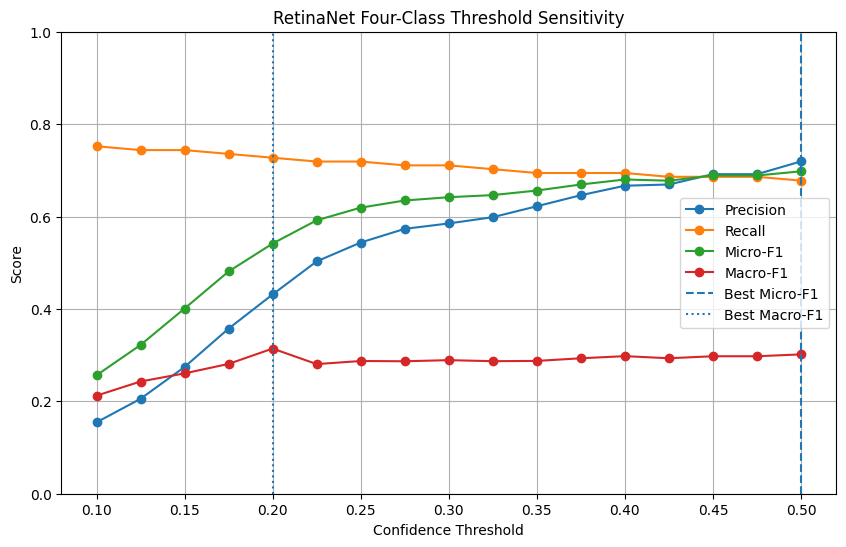

In [21]:

FINE_THRESHOLDS = np.round(
    np.arange(0.10, 0.5001, 0.025),
    3
)

fine_results = []

for threshold in FINE_THRESHOLDS:

    cm = make_confusion_matrix(float(threshold))

    metrics = calculate_metrics(
        cm,
        float(threshold)
    )

    fine_results.append(metrics)


fine_df = pd.DataFrame(fine_results)

print("FINE CONFIDENCE THRESHOLD SWEEP")

display(
    fine_df[
        [
            "Threshold",
            "Precision",
            "Recall",
            "Micro-F1",
            "Macro-F1"
        ]
    ].round(4)
)


# Select best micro-F1 threshold
best_micro = fine_df.loc[
    fine_df["Micro-F1"].idxmax()
]

# Select best macro-F1 threshold
best_macro = fine_df.loc[
    fine_df["Macro-F1"].idxmax()
]

print("\nBEST MICRO-F1 THRESHOLD")
print(f"Threshold: {best_micro['Threshold']:.3f}")
print(f"Precision: {best_micro['Precision']:.4f}")
print(f"Recall: {best_micro['Recall']:.4f}")
print(f"Micro-F1: {best_micro['Micro-F1']:.4f}")

print("\nBEST MACRO-F1 THRESHOLD")
print(f"Threshold: {best_macro['Threshold']:.3f}")
print(f"Macro-F1: {best_macro['Macro-F1']:.4f}")


# Plot threshold sensitivity
plt.figure(figsize=(10, 6))

for metric in [
    "Precision",
    "Recall",
    "Micro-F1",
    "Macro-F1"
]:

    plt.plot(
        fine_df["Threshold"],
        fine_df[metric],
        marker="o",
        label=metric
    )

plt.axvline(
    best_micro["Threshold"],
    linestyle="--",
    label="Best Micro-F1"
)

plt.axvline(
    best_macro["Threshold"],
    linestyle=":",
    label="Best Macro-F1"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title(
    "RetinaNet Four-Class Threshold Sensitivity"
)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.savefig(
    run_dir / "fine_threshold_sensitivity.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# Save results
fine_df.to_csv(
    run_dir / "fine_threshold_comparison.csv",
    index=False
)



## 10. Confidence Threshold Sensitivity Analysis

A finer confidence threshold sweep from 0.10 to 0.50, with increments of 0.025, is performed to investigate how threshold selection affects detection performance.

The thresholds producing the highest micro-F1 and macro-F1 scores are identified. Per-class recall is also examined to determine whether improving overall performance causes minority defect classes to be overlooked.

The selected thresholds will be used as validation operating points for the final model comparison.


PER-CLASS RECALL


,Threshold,loose-meat,packaging-error,twisted-meat,unsealed
0,0.100,0.3333,0.5294,0.0,0.8889
1,0.125,0.3333,0.5000,0.0,0.8889
2,0.150,0.3333,0.5000,0.0,0.8889
3,0.175,0.3333,0.4706,0.0,0.8889
4,0.200,0.3333,0.4412,0.0,0.8889
5,0.225,0.0000,0.4412,0.0,0.8889
6,0.250,0.0000,0.4412,0.0,0.8889
7,0.275,0.0000,0.4118,0.0,0.8889
8,0.300,0.0000,0.4118,0.0,0.8889
9,0.325,0.0000,0.3824,0.0,0.8889


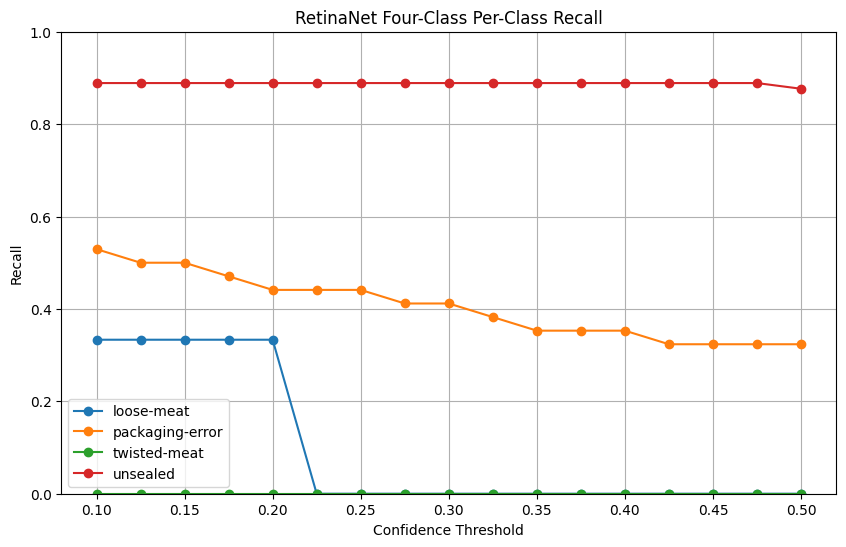


RECALL AT SELECTED THRESHOLDS


,Threshold,loose-meat,packaging-error,twisted-meat,unsealed
4,0.2,0.3333,0.4412,0.0,0.8889
16,0.5,0.0000,0.3235,0.0,0.8765


In [19]:

# Create recall table for each defect class
recall_columns = [
    class_name + "_Recall"
    for class_name in CLASS_NAMES
]

recall_df = fine_df[
    ["Threshold"] + recall_columns
].copy()

recall_df.columns = (
    ["Threshold"] + CLASS_NAMES
)

print("PER-CLASS RECALL")
display(recall_df.round(4))


# Plot per-class recall
plt.figure(figsize=(10, 6))

for class_name in CLASS_NAMES:

    plt.plot(
        recall_df["Threshold"],
        recall_df[class_name],
        marker="o",
        label=class_name
    )

plt.xlabel("Confidence Threshold")
plt.ylabel("Recall")
plt.title(
    "RetinaNet Four-Class Per-Class Recall"
)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.savefig(
    run_dir / "per_class_recall.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# Compare recall at best thresholds
selected_thresholds = sorted(set([
    float(best_micro["Threshold"]),
    float(best_macro["Threshold"])
]))

print("\nRECALL AT SELECTED THRESHOLDS")

display(
    recall_df[
        recall_df["Threshold"].isin(
            selected_thresholds
        )
    ].round(4)
)



## 11. Computational Performance Evaluation

The computational requirements of RetinaNet are evaluated using parameter count, model checkpoint size, inference time, frames per second (FPS), training time and GPU memory usage.

These measurements will later be compared with YOLOv8n and Faster R-CNN to investigate the trade-off between detection performance and computational efficiency.

All inference benchmarks should use comparable hardware and testing conditions.


In [20]:

# ---------------------------------------
# Model complexity
# ---------------------------------------
parameter_count = sum(
    p.numel()
    for p in retinanet.parameters()
)

checkpoint_size_mb = (
    best_model_path.stat().st_size / (1024 ** 2)
)

print("Model parameters:", parameter_count)
print(
    "Checkpoint size (MB):",
    round(checkpoint_size_mb, 2)
)


# ---------------------------------------
# Inference benchmark
# ---------------------------------------
retinanet.eval()

# Use one validation image
sample_image, _ = valid_dataset[0]

sample_image = sample_image.to(device)

# Warm up GPU
with torch.no_grad():

    for _ in range(10):
        _ = retinanet([sample_image])

# Synchronise GPU before timing
if device.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()


inference_times = []

with torch.no_grad():

    for _ in range(50):

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        _ = retinanet([sample_image])

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = (
            time.perf_counter() - start
        )

        inference_times.append(elapsed * 1000)


# Median inference time in milliseconds
median_inference_ms = float(
    np.median(inference_times)
)

# Approximate single-image throughput
fps = 1000 / median_inference_ms


# GPU memory usage
if device.type == "cuda":

    peak_gpu_mb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )

else:
    peak_gpu_mb = np.nan


# ---------------------------------------
# Save computational comparison
# ---------------------------------------
compute_results = pd.DataFrame([{
    "Model": "RetinaNet ResNet50-FPN V2",
    "Parameters": parameter_count,
    "Checkpoint_MB": checkpoint_size_mb,
    "Inference_ms": median_inference_ms,
    "FPS": fps,
    "Peak_GPU_MB": peak_gpu_mb,
    "Training_seconds": (
        training_seconds
        if "training_seconds" in globals()
        else np.nan
    )
}])

print("COMPUTATIONAL PERFORMANCE")

display(compute_results.round(4))

compute_results.to_csv(
    run_dir / "computational_performance.csv",
    index=False
)


Model parameters: 36414865
Checkpoint size (MB): 277.31
COMPUTATIONAL PERFORMANCE


,Model,Parameters,Checkpoint_MB,Inference_ms,FPS,Peak_GPU_MB,Training_seconds
0,RetinaNet ResNet50-FPN V2,36414865,277.308,65.2514,15.3253,783.0928,2321.4753
